# 베이스라인 — 품목만으로 예측 (5_품목만)

CLAUDE.md 베이스라인 목록의 "품목만으로 예측". 이 칼럼 하나만 알 때 검출을 얼마나 가려낼 수 있는지 잰다. LIMS 칼럼 5개를 쓴 `2_바로학습` 이 이 베이스라인을 넘지 못하면 모델을 쓸 이유가 없다.

| 항목 | 내용 |
|---|---|
| 입력 | `data/X.parquet`, `data/y.parquet` (`EXP/1/1_데이터정제.ipynb` 에서 저장) |
| 피처 | `train_prdlst_code` 1개 — 모델팀 학습용 품목코드(정의서: "학습용 품목코드. C계열 lv3, 그 외 lv2"), 52종 + `'기타'`(코드가 비어 있던 170행) |
| 방법 | ML 학습 없음. train 기간의 품목별 검출 비율(검출 수 ÷ 행 수)을 그 품목 시료의 예측 확률로 쓴다 |
| 결측 | 없음 — 원자료에서 `train_prdlst_code` 가 비어 있던 170행(`train_prdlst_nm` 은 '기타')은 `1_데이터정제.ipynb` 에서 `'기타'` 로 채워져 한 그룹이다(2026-10-01, 이전에는 이 노트북에서 `(결측)` 으로 묶음) |
| train 에 없는 품목 | train 전체 검출 비율을 준다 |
| 분할 | `2_바로학습` 과 같음 — train ~2024-06-30 · val 2024-07-01~2025-06-30 · test 2025-07-01~2026-06-30(고정) |
| val 의 쓰임 | 임계값을 고르는 데만 쓴다 |
| 임계값 | 0.5 · val 에서 F1 최대 · val 에서 F2 최대 — 세 가지 결과를 모두 기록 |
| 기록 지표 | 임계값, accuracy, precision, recall, f1, f2, roc_auc, pr_auc, 혼동행렬(TP·FN·FP·TN), 전체 건수 — 모든 비율은 0~1 소수 |
| 결과 기록 | MLflow 실험 `리스테리아_EXP1` 의 run `5_품목만` (10절). 파일로 따로 저장하지 않는다 |

> **왜 ML 이 없나**: 입력이 품목코드 하나라 어떤 모델이든 결국 "품목 → 확률" 표를 배우는 것과 같다. 그 표를 가장 곧바로 추정하는 방법이 train 의 품목별 검출 비율이다.
>
> **원본 품목코드 `prdlst_code`(1,251종)를 쓰지 않은 이유**: train 에 없는 코드가 val 에 45종 137행, test 에 66종 473행 나온다. `train_prdlst_code` 는 train 에 없는 값이 val 21행·test 14행(1종, 검출 0건)뿐이다.
>
> **주의**
> - train 에서 검출이 한 번도 없는 품목(아래 5절 표에서 `train 검출` 0)은 예측 확률이 0 이다. 행이 아주 적은 품목도 비율이 그대로 쓰인다(보정하지 않음).
> - 이 파일의 `train_prdlst_code` 는 2026-09-08 추출 값이라 현재 DB `ready_data.hazard_preprocessed_data` 와 9,236행 다르다(작업기록 2026-09-22). `2_바로학습` 과 같은 값을 쓰므로 둘의 비교에는 문제없다.

## 1. 데이터 불러오기

`2_바로학습` 과 같다. `y` 파일(`lims_data_key` + `judge_result`)을 `lims_data_key` 로 X 의 행 순서에 맞춘 뒤 `judge_result` 한 칼럼만 쓴다.

In [1]:
import pandas as pd

X_path = r"C:\Users\NT751\Desktop\천영진\리스테리아ML\data\X.parquet"
y_path = r"C:\Users\NT751\Desktop\천영진\리스테리아ML\data\y.parquet"

X = pd.read_parquet(X_path)
y_df = pd.read_parquet(y_path)   # lims_data_key + judge_result

# y 를 행 키 lims_data_key 로 X 의 행 순서에 맞춘 뒤, 타깃 judge_result 한 칼럼(Series)만 쓴다
assert y_df['lims_data_key'].is_unique, 'y 의 lims_data_key 가 중복됨'
y = (y_df.set_index('lims_data_key')['judge_result']
         .reindex(X['lims_data_key'])
         .set_axis(X.index))
assert y.notna().all(), 'X 의 lims_data_key 중 y 에 없는 행이 있음'

print('X', X.shape, '| y', y.shape, '| 검출', int(y.sum()))

X (676537, 11) | y (676537,) | 검출 1969


## 2. 실험 설정

분할 날짜·MLflow 기록 위치는 `2_바로학습` 과 같다. 무작위 요소가 없어 seed·장치 설정은 없다(몇 번을 돌려도 같은 결과).

In [2]:
import json
import logging
import sys
import tempfile
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import sklearn
import os
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')   # mlflow 가 찍는 LLM 추적 안내 문구 끄기
import mlflow
from dotenv import dotenv_values
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
)

# 분할 날짜 — 2_바로학습 과 같다 (mnfctur_de 기준, 양 끝 날짜 포함)
TRAIN_END = '2024-06-30'
VAL_START, VAL_END = '2024-07-01', '2025-06-30'
TEST_START, TEST_END = '2025-07-01', '2026-06-30'   # readme 고정 기간

KEY_COL = 'lims_data_key'   # 행 키
DATE_COL = 'mnfctur_de'     # 분할 기준
MODEL = '품목별비율'         # 이 베이스라인의 이름 — MLflow 자식 run 이름에 쓴다
MODELS = [MODEL]

# MLflow — 2_바로학습 과 같은 기록 위치
ENV_PATH = Path(r'C:\Users\NT751\Desktop\천영진\리스테리아ML\.env')
PROJECT_DIR = ENV_PATH.parent                         # 리스테리아ML/
MLFLOW_URI = dotenv_values(ENV_PATH).get('AFLA_MLFLOW_URI')   # .env 에서 이 키 하나만 읽는다
assert MLFLOW_URI, '.env 에 AFLA_MLFLOW_URI 가 없음'
if MLFLOW_URI.startswith('sqlite:///') and not Path(MLFLOW_URI.removeprefix('sqlite:///')).is_absolute():
    # 상대경로면 노트북을 연 폴더마다 DB 가 따로 생긴다 → .env 가 있는 리스테리아ML/ 기준으로 고정
    MLFLOW_URI = 'sqlite:///' + (PROJECT_DIR / MLFLOW_URI.removeprefix('sqlite:///')).as_posix()
MLFLOW_ARTIFACTS = PROJECT_DIR / 'mlruns'
MLFLOW_EXPERIMENT = '리스테리아_EXP1'
RUN_NAME = '5_품목만'
LOG_TO_MLFLOW = False   # True 로 바꾸면 10절에서 MLflow 에 기록한다(실행할 때마다 새 run 이 쌓임). False 면 출력만 본다

logging.getLogger('alembic').setLevel(logging.WARNING)
mlflow.set_tracking_uri(MLFLOW_URI)
if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
    mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=MLFLOW_ARTIFACTS.as_uri())
mlflow.set_experiment(MLFLOW_EXPERIMENT)

plt.rcParams['font.family'] = 'Malgun Gothic'   # 그림 속 한글
plt.rcParams['axes.unicode_minus'] = False

print('MLflow:', MLFLOW_URI, '| 실험', MLFLOW_EXPERIMENT, '| run', RUN_NAME)

MLflow: sqlite:///C:/Users/NT751/Desktop/천영진/리스테리아ML/mlflow.db | 실험 리스테리아_EXP1 | run 5_품목만


## 3. 데이터 분할 (시간순)

`2_바로학습` 과 같은 기간으로 나눈다. 비율표를 전체 데이터로 계산하면 test 의 정답이 예측 확률에 섞여 들어가므로(누수), 비율은 **train 으로만** 계산한다.

| 구간 | 기간 | 쓰임 |
|---|---|---|
| train | 2015-04-07 ~ 2024-06-30 | 검출 비율표 계산 (= 학습) |
| val | 2024-07-01 ~ 2025-06-30 | 임계값 고르기 |
| test | 2025-07-01 ~ 2026-06-30 | 최종 성능. `2_바로학습` 과 같은 기간이라 바로 비교할 수 있다 |

In [3]:
assert len(X) == len(y) and X.index.equals(y.index), 'X 와 y 의 행이 맞지 않음'

d = X[DATE_COL]
masks = {
    'train': d <= pd.Timestamp(TRAIN_END),
    'val':   d.between(pd.Timestamp(VAL_START), pd.Timestamp(VAL_END)),
    'test':  d.between(pd.Timestamp(TEST_START), pd.Timestamp(TEST_END)),
}
n_assigned = sum(m.astype(int) for m in masks.values())
assert n_assigned.max() == 1, '두 구간에 겹치는 행이 있음'
print('어느 구간에도 속하지 않는 행:', int((n_assigned == 0).sum()))

split_summary = pd.DataFrame([
    {'구간': s, '시작일': d[m].min().date(), '종료일': d[m].max().date(),
     '행 수': int(m.sum()), '검출(1)': int(y[m].sum()),
     '검출 비율': round(y[m].mean(), 5)}
    for s, m in masks.items()
])
display(split_summary)
assert (split_summary['검출(1)'] > 0).all(), '검출이 0건인 구간이 있음'

어느 구간에도 속하지 않는 행: 0


,구간,시작일,종료일,행 수,검출(1),검출 비율
0,train,2015-04-07,2024-06-30,497896,1491,0.00299
1,val,2024-07-01,2025-06-30,87553,191,0.00218
2,test,2025-07-01,2026-06-30,91088,287,0.00315


## 4. 입력 칼럼 — 품목

`train_prdlst_code`(모델팀 학습용 품목코드) 하나만 쓴다. 원자료에서 코드가 비어 있던 170행은 `X.parquet` 에 `'기타'` 로 들어 있어(`1_데이터정제.ipynb`) 결측이 없다. val·test 에 train 에 없던 품목이 몇 행인지 확인한다(그 행은 6절에서 train 전체 검출 비율을 받는다).

In [4]:
FEATURE = 'train_prdlst_code'
assert X[FEATURE].notna().all()   # 코드가 비어 있던 170행은 1_데이터정제에서 '기타' 로 채워짐
feat = X[FEATURE].astype(object).rename(FEATURE)

SPLITS = ['train', 'val', 'test']
feats = {s: feat[masks[s]] for s in SPLITS}
ys = {s: y[masks[s]] for s in SPLITS}

train_values = set(feats['train'])
for s in SPLITS:
    unseen = ~feats[s].isin(train_values)
    print(f'{s:5s} 행 {len(feats[s]):>7,} | {FEATURE} 종류 {feats[s].nunique():>3} | '
          f'train 에 없는 값 {feats[s][unseen].nunique()}종 {int(unseen.sum()):,}행 (검출 {int(ys[s][unseen].sum())})')

train 행 497,896 | train_prdlst_code 종류  52 | train 에 없는 값 0종 0행 (검출 0)
val   행  87,553 | train_prdlst_code 종류  44 | train 에 없는 값 1종 21행 (검출 0)
test  행  91,088 | train_prdlst_code 종류  43 | train 에 없는 값 1종 14행 (검출 0)


## 5. 학습 = train 기간의 검출 비율표 계산

값마다 train 의 `검출 수 ÷ 행 수` 를 계산한다. 이 표가 곧 모델이다. train 에 없는 값에는 train 전체 검출 비율(`FALLBACK`)을 준다. 비율은 0~1 소수다.

In [5]:
t0 = time.perf_counter()
g = pd.DataFrame({FEATURE: feats['train'], 'y': ys['train']}).groupby(FEATURE)['y']
rate_table = pd.DataFrame({'train 행 수': g.size(), 'train 검출': g.sum()})
rate_table['train 검출 비율'] = rate_table['train 검출'] / rate_table['train 행 수']
FALLBACK = float(ys['train'].mean())   # train 에 없는 값에 줄 확률 = train 전체 검출 비율
fit_seconds = {MODEL: round(time.perf_counter() - t0, 3)}
rate_table = rate_table.sort_values(['train 검출 비율', 'train 행 수'], ascending=False)

print(f'{FEATURE} {len(rate_table)}종 | 검출 0 인 값 {int((rate_table["train 검출"] == 0).sum())}종 | '
      f'train 전체 검출 비율(FALLBACK) {FALLBACK:.5f}')
display(rate_table.round({'train 검출 비율': 5}))

train_prdlst_code 52종 | 검출 0 인 값 37종 | train 전체 검출 비율(FALLBACK) 0.00299


,train 행 수,train 검출,train 검출 비율
train_prdlst_code,,,
A0700000000000,57,8,0.14035
A1200000000000,43,2,0.04651
Z2700000000000,20608,552,0.02679
B0100000000000,1318,25,0.01897
C0319000000000,4103,25,0.00609
A0400000000000,274,1,0.00365
C0316000000000,81357,251,0.00309
Z3800000000000,195696,534,0.00273
B0200000000000,6088,16,0.00263


## 6. val·test 확률 예측

각 시료에 그 값의 train 검출 비율을 붙인다. 예측 확률의 종류는 비율표의 값 개수만큼뿐이다.

In [6]:
proba = {}
for s in ['val', 'test']:
    p = feats[s].map(rate_table['train 검출 비율']).astype(float)
    n_fallback = int(p.isna().sum())
    proba[s] = pd.DataFrame({MODEL: p.fillna(FALLBACK)}, index=feats[s].index)
    print(f'{s:4s} 예측 확률 종류 {proba[s][MODEL].nunique()}개 | train 전체 비율로 채운 행 {n_fallback:,}')

val  예측 확률 종류 16개 | train 전체 비율로 채운 행 21
test 예측 확률 종류 16개 | train 전체 비율로 채운 행 14


## 7. 임계값 정하기 — val 에서만

`2_바로학습` 과 같은 규칙이다. 예측 확률이 임계값 **이상**이면 검출(1)로 판정한다.

| 규칙 | 정하는 방법 |
|---|---|
| `0.5` | 고정. 검출 비율이 모두 0.5 보다 훨씬 작아 **아무것도 검출로 판정하지 않는다**(TP 0 이 정상) |
| `F1최대` | val 에서 F1 이 가장 큰 임계값 |
| `F2최대` | val 에서 F2 가 가장 큰 임계값 (recall 을 더 무겁게 봄) |

예측 확률 종류가 적어서 후보 임계값도 그 개수뿐이다. 그래서 임계값을 바꾸면 "이 값 이상인 그룹 전체"가 한꺼번에 검출로 바뀐다.

In [7]:
def fbeta_curve(precision, recall, beta):
    b2 = beta ** 2
    denom = b2 * precision + recall
    return np.divide((1 + b2) * precision * recall, denom,
                     out=np.zeros_like(denom, dtype=float), where=denom > 0)

def best_threshold(y_true, p, beta):
    """Fβ 가 가장 큰 임계값과 그때의 Fβ (판정: p >= 임계값)"""
    precision, recall, thr = precision_recall_curve(y_true, p)
    f = fbeta_curve(precision[:-1], recall[:-1], beta)   # 마지막 점은 짝이 되는 임계값이 없어 제외
    i = int(np.argmax(f))
    return float(thr[i]), float(f[i])

thresholds = {}
rows = []
for name in MODELS:
    t_f1, f1_val = best_threshold(ys['val'], proba['val'][name], beta=1)
    t_f2, f2_val = best_threshold(ys['val'], proba['val'][name], beta=2)
    thresholds[name] = {'0.5': 0.5, 'F1최대': t_f1, 'F2최대': t_f2}
    rows.append({'모델': name, 'F1최대 임계값': t_f1, 'val F1': f1_val,
                 'F2최대 임계값': t_f2, 'val F2': f2_val})

display(pd.DataFrame(rows).round({'F1최대 임계값': 6, 'val F1': 4, 'F2최대 임계값': 6, 'val F2': 4}))

,모델,F1최대 임계값,val F1,F2최대 임계값,val F2
0,품목별비율,0.026786,0.0234,0.018968,0.0509


## 8. 평가 — 임계값 규칙별 지표

`2_바로학습` 과 같은 지표다. 모든 비율은 0~1 소수다. roc_auc·pr_auc 는 확률의 순서만 보므로 세 규칙에서 같고, 모델끼리(베이스라인 vs `2_바로학습`) 비교할 때 기준이 된다. pr_auc 를 무작위로 찍을 때의 기대값은 그 구간의 검출 비율(test 0.00315)이다.

In [8]:
def evaluate(y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        '임계값': threshold,
        '전체 건수': len(y_true),
        '실제 검출': int(y_true.sum()),
        '예측 양성 수': int(tp + fp),
        'accuracy': accuracy_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'recall': recall_score(y_true, pred, zero_division=0),
        'f1': f1_score(y_true, pred, zero_division=0),
        'f2': fbeta_score(y_true, pred, beta=2, zero_division=0),
        'roc_auc': roc_auc_score(y_true, p),
        'pr_auc': average_precision_score(y_true, p),
        'TP': int(tp), 'FN': int(fn), 'FP': int(fp), 'TN': int(tn),
    }

records = []
for name in MODELS:
    for rule, t in thresholds[name].items():
        for s in ['val', 'test']:
            records.append({'모델': name, '구간': s, '임계값 규칙': rule,
                            **evaluate(ys[s], proba[s][name], t)})
metrics = pd.DataFrame(records)

SCORE_COLS = ['accuracy', 'precision', 'recall', 'f1', 'f2', 'roc_auc', 'pr_auc']

def show_metrics(split):
    df = metrics[metrics['구간'] == split].drop(columns='구간').reset_index(drop=True)
    display(df.round({**{c: 4 for c in SCORE_COLS}, '임계값': 6}))

### 8-1. test — 최종 성능 (2025-07-01 ~ 2026-06-30)

In [9]:
show_metrics('test')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,품목별비율,0.5,0.500000,91088,287,0,0.9968,0.0000,0.0000,0.0000,0.0000,0.6638,0.0068,0,287,0,90801
1,품목별비율,F1최대,0.026786,91088,287,4597,0.9475,0.0107,0.1707,0.0201,0.0426,0.6638,0.0068,49,238,4548,86253
2,품목별비율,F2최대,0.018968,91088,287,4835,0.9449,0.0103,0.1742,0.0195,0.0418,0.6638,0.0068,50,237,4785,86016


### 8-2. val — 참고 (임계값을 고른 구간)

In [10]:
show_metrics('val')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,품목별비율,0.5,0.500000,87553,191,0,0.9978,0.0000,0.0000,0.0000,0.0000,0.6787,0.0059,0,191,0,87362
1,품목별비율,F1최대,0.026786,87553,191,3481,0.9590,0.0124,0.2251,0.0234,0.0506,0.6787,0.0059,43,148,3438,83924
2,품목별비율,F2최대,0.018968,87553,191,3656,0.9571,0.0123,0.2356,0.0234,0.0509,0.6787,0.0059,45,146,3611,83751


## 9. 그림

1. **val 임계값별 precision·recall·F1·F2** — 고른 임계값(F1·F2 곡선의 최고점)이 어디인지.
2. **test PR 곡선** — 회색 가로선은 아무렇게나 찍을 때의 기준(test 검출 비율).

그림은 10절에서 MLflow 에 올린다(파일로 따로 저장하지 않음). 임계값 가로축과 PR 곡선 세로축은 값이 0 근처에 몰려 있어 로그 눈금을 쓴다.

In [11]:
# 그림 공통 색·선 (2_바로학습 과 같음)
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
MODEL_COLOR = {MODEL: '#2a78d6'}
METRIC_COLOR = {'precision': '#2a78d6', 'recall': '#eb6834', 'F1': '#1baf7a', 'F2': '#eda100'}
SPLIT_COLOR = {'train': '#2a78d6', 'val': '#eb6834', 'test': '#1baf7a'}
PLAIN = FuncFormatter(lambda v, _: f'{v:g}')   # 로그 눈금 숫자를 0.001·0.01·0.1·1 로 표시
FIGURES = {}   # 파일 이름 → 그림. 10절에서 MLflow 에 올린다

def style_axes(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=AXIS, labelcolor=INK2, labelsize=9)

### 9-1. val — 임계값에 따른 precision·recall·F1·F2

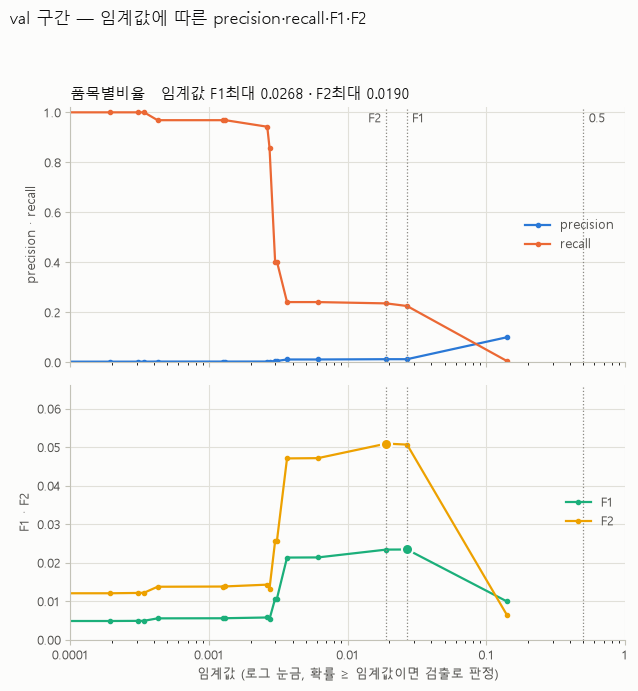

In [12]:
fig, axes = plt.subplots(2, len(MODELS), figsize=(6.4 * len(MODELS), 7.0),
                         sharex=True, sharey='row', facecolor=SURFACE, squeeze=False)
f_max, x_lo = 0, 1e-4
for j, name in enumerate(MODELS):
    precision, recall, thr = precision_recall_curve(ys['val'], proba['val'][name])
    precision, recall = precision[:-1], recall[:-1]
    curves = {'precision': precision, 'recall': recall,
              'F1': fbeta_curve(precision, recall, 1), 'F2': fbeta_curve(precision, recall, 2)}
    f_max = max(f_max, curves['F1'].max(), curves['F2'].max())
    if (thr > 0).any():
        x_lo = min(x_lo, 10 ** np.floor(np.log10(thr[thr > 0].min())))
    t1, t2 = thresholds[name]['F1최대'], thresholds[name]['F2최대']

    ax_top, ax_bot = axes[0, j], axes[1, j]
    for ax, keys in [(ax_top, ['precision', 'recall']), (ax_bot, ['F1', 'F2'])]:
        style_axes(ax)
        ax.set_xscale('log')
        for k in keys:   # 예측 확률 종류가 적어 계단처럼 보이도록 점도 찍는다
            ax.plot(thr, curves[k], color=METRIC_COLOR[k], linewidth=1.6, marker='o', markersize=3, label=k)
        for t in {t1, t2, 0.5}:   # 세로 점선: 고른 임계값과 0.5
            ax.axvline(t, color=MUTED, linewidth=0.9, linestyle=':')

    for t, k in [(t1, 'F1'), (t2, 'F2')]:
        ax_bot.plot(t, curves[k][np.searchsorted(thr, t)], 'o', markersize=8, color=METRIC_COLOR[k],
                    markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)

    if t1 == t2:
        marks = [(t1, 'F1·F2', 'left')]
    else:
        (lo, lo_name), (hi, hi_name) = sorted([(t1, 'F1'), (t2, 'F2')])
        marks = [(lo, lo_name, 'right'), (hi, hi_name, 'left')]
    for t, text, ha in marks + [(0.5, '0.5', 'left')]:
        ax_top.text(t, 1.0, f' {text} ', ha=ha, va='top', color=INK2, fontsize=9)

    ax_top.set_title(f'{name}   임계값 F1최대 {t1:.4f} · F2최대 {t2:.4f}', loc='left', color=INK, fontsize=10.5)
    ax_bot.set_xlabel('임계값 (로그 눈금, 확률 ≥ 임계값이면 검출로 판정)', color=INK2, fontsize=9)

for ax in axes.flat:
    ax.set_xlim(x_lo, 1)
    ax.legend(frameon=False, fontsize=9, labelcolor=INK2, loc='center right')
    ax.xaxis.set_major_formatter(PLAIN)
axes[0, 0].set_ylim(0, 1.02)
axes[1, 0].set_ylim(0, f_max * 1.3)
axes[0, 0].set_ylabel('precision · recall', color=INK2, fontsize=9)
axes[1, 0].set_ylabel('F1 · F2', color=INK2, fontsize=9)

fig.suptitle('val 구간 — 임계값에 따른 precision·recall·F1·F2', x=0.01, ha='left', color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
FIGURES['val_threshold_curves.png'] = fig
plt.show()

### 9-2. test — PR 곡선

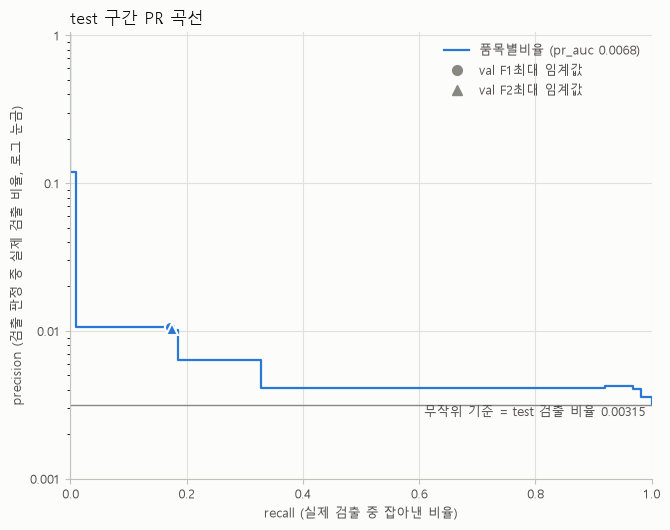

In [13]:
fig, ax = plt.subplots(figsize=(6.8, 5.4), facecolor=SURFACE)
style_axes(ax)
ax.set_yscale('log', nonpositive='mask')
pos_rate = ys['test'].mean()

for name in MODELS:
    precision, recall, _ = precision_recall_curve(ys['test'], proba['test'][name])
    ap = average_precision_score(ys['test'], proba['test'][name])
    ax.plot(recall, precision, drawstyle='steps-post', color=MODEL_COLOR[name], linewidth=1.6,
            label=f'{name} (pr_auc {ap:.4f})')
    # val 에서 고른 임계값이 test 에서 찍힌 자리 (TP 가 0 이면 precision 0 이라 로그 눈금에 못 찍음)
    for rule, marker in [('F1최대', 'o'), ('F2최대', '^')]:
        row = metrics[(metrics['모델'] == name) & (metrics['구간'] == 'test')
                      & (metrics['임계값 규칙'] == rule)].iloc[0]
        if row['TP'] > 0:
            ax.plot(row['recall'], row['precision'], marker=marker, markersize=8, linestyle='none',
                    color=MODEL_COLOR[name], markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)

ax.axhline(pos_rate, color=MUTED, linewidth=1)
ax.text(0.99, pos_rate, f'무작위 기준 = test 검출 비율 {pos_rate:.5f}', transform=ax.get_yaxis_transform(),
        ha='right', va='top', color=INK2, fontsize=9)

ax.set_xlim(0, 1)
ax.set_ylim(1e-3, 1.05)
ax.yaxis.set_major_formatter(PLAIN)
ax.set_xlabel('recall (실제 검출 중 잡아낸 비율)', color=INK2, fontsize=9)
ax.set_ylabel('precision (검출 판정 중 실제 검출 비율, 로그 눈금)', color=INK2, fontsize=9)
ax.set_title('test 구간 PR 곡선', loc='left', color=INK, fontsize=12)
marker_keys = [
    Line2D([], [], marker='o', linestyle='none', color=MUTED, markersize=7, label='val F1최대 임계값'),
    Line2D([], [], marker='^', linestyle='none', color=MUTED, markersize=7, label='val F2최대 임계값'),
]
ax.legend(handles=ax.get_legend_handles_labels()[0] + marker_keys,
          frameon=False, fontsize=9, labelcolor=INK2, loc='upper right')
fig.tight_layout()
FIGURES['test_pr_curve.png'] = fig
plt.show()

## 10. MLflow 에 기록

`2_바로학습` 과 같은 실험 `리스테리아_EXP1` 에 같은 구조·같은 지표 이름으로 기록한다. MLflow 화면에서 `2_바로학습` 의 자식 run 과 나란히 놓고 비교할 수 있다.

| 기록 단위 | run 이름 | params (조건) | metrics·artifacts (결과) |
|---|---|---|---|
| 부모 run 1개 | `5_품목만` | 입력 파일·수정 시각, 분할 기간·건수·검출 수, 피처 정의, 방법, train 에 없는 값 처리 | 그림, 비율표 `rate_table.csv`(= 이 모델 자체), 지표 전체 표 `metrics.csv`, 시료별 예측 확률 `predictions.parquet`, 설정 전체 `config.json` |
| 자식 run 3개 (임계값 규칙별) | `5_품목만 / 품목별비율 / F2최대` 처럼 `노트북 / 모델 / 규칙` | 입력 데이터 한 줄 설명 `input`, 모델, 임계값 규칙, 임계값, 피처 | `2_바로학습` 과 같은 이름의 지표 — `val_`·`test_` + accuracy, precision, recall, f1, f2, roc_auc, pr_auc, TP, FN, FP, TN, `n_total`, `n_pos`, `n_pred_pos`, `threshold`, `fit_seconds` |

보는 법: `py -m mlflow ui --backend-store-uri "sqlite:///C:/Users/NT751/Desktop/천영진/리스테리아ML/mlflow.db"` → http://127.0.0.1:5000 → 왼쪽 위 **Model training** → `리스테리아_EXP1`.

`LOG_TO_MLFLOW`(2절)가 `False` 면 기록하지 않고 출력만 본다(다시 실행해도 MLflow 에 같은 run 이 쌓이지 않음). 기록할 때만 `True` 로 바꾼다.

In [14]:
# 기록할 내용 준비
INPUT = '품목 (train_prdlst_code)'   # 입력 데이터 한 줄 설명 — MLflow 에서 run 을 구별하는 데 쓴다
def file_mtime(path):
    return datetime.fromtimestamp(Path(path).stat().st_mtime).isoformat(timespec='seconds')

parent_params = {
    'input': INPUT,
    'data.X': X_path, 'data.X_mtime': file_mtime(X_path), 'data.X_shape': str(X.shape),
    'data.y': y_path, 'data.y_mtime': file_mtime(y_path),
    **{f'split.{r["구간"]}': f'{r["시작일"]}~{r["종료일"]} | {r["행 수"]:,}행 | 검출 {r["검출(1)"]:,}건'
       for r in split_summary.to_dict('records')},
    'features': json.dumps([FEATURE], ensure_ascii=False),
    'n_features': 1,
    'feature_def': 'train_prdlst_code (모델팀 학습용 품목코드). 코드가 비어 있던 170행은 "기타"(1_데이터정제), train 에 없는 값은 train 전체 검출 비율',
    'method': 'train 기간 값별 검출 비율(검출 수 ÷ 행 수)을 예측 확률로 사용 — ML 학습 없음',
    'n_groups': len(rate_table),
    'fallback': f'train 에 없는 값 → train 전체 검출 비율 {FALLBACK:.6f}',
    'seed': '없음 (무작위 요소 없음)',
    'tuning': '없음',
    'imbalance': '없음',
    'threshold_rules': '0.5 / val F1최대 / val F2최대 (판정: 확률 >= 임계값)',
}

config = {
    'params': parent_params,
    'split': split_summary.astype({'시작일': str, '종료일': str}).to_dict('records'),
    'rate_table': {str(k): v for k, v in rate_table.to_dict('index').items()},
    'fallback': FALLBACK,
    'thresholds': thresholds,
    'libraries': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
                  'scikit-learn': sklearn.__version__, 'mlflow': mlflow.__version__},
}

pred_out = pd.concat([   # predictions.parquet — val·test 시료별 예측 확률
    pd.DataFrame({
        KEY_COL: X.loc[proba[s].index, KEY_COL].to_numpy(),
        '구간': s,
        DATE_COL: X.loc[proba[s].index, DATE_COL].to_numpy(),
        FEATURE: feats[s].astype(str).to_numpy(),
        'y': ys[s].to_numpy(),
        **{f'p_{name}': proba[s][name].to_numpy() for name in MODELS},
    })
    for s in ['val', 'test']
], ignore_index=True)

# metrics 표 칼럼 → MLflow metric 이름 (2_바로학습 과 같음, 앞에 val_·test_ 가 붙는다)
METRIC_KEYS = {c: c for c in SCORE_COLS + ['TP', 'FN', 'FP', 'TN']}
METRIC_KEYS.update({'전체 건수': 'n_total', '실제 검출': 'n_pos', '예측 양성 수': 'n_pred_pos'})
BOM = chr(0xFEFF)   # CSV 맨 앞에 붙이면 엑셀에서 한글이 깨지지 않는다

print('부모 run params', len(parent_params), '개 | 비율표', rate_table.shape, '| 예측 확률', pred_out.shape)

부모 run params 19 개 | 비율표 (52, 3) | 예측 확률 (178641, 6)


In [15]:
# MLflow 에 기록 — 부모 run 1개 + 자식 run 3개(임계값 규칙별)
NOTEBOOK = r'리스테리아ML\EXP\1\5_품목만.ipynb'
STAGE = '베이스라인 — 품목만 (train 품목별 검출 비율)'

if LOG_TO_MLFLOW:
    with mlflow.start_run(run_name=RUN_NAME) as parent:
        mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE, 'mlflow.note.content': STAGE})
        mlflow.log_params(parent_params)
        for fname, fig in FIGURES.items():
            mlflow.log_figure(fig, f'figures/{fname}')
        mlflow.log_text(BOM + rate_table.to_csv(), 'rate_table.csv')
        mlflow.log_text(BOM + metrics.to_csv(index=False), 'metrics.csv')
        mlflow.log_dict(config, 'config.json')
        with tempfile.TemporaryDirectory() as tmp:   # 임시 폴더에 쓴 뒤 MLflow 로 옮긴다 (프로젝트 폴더에 안 남음)
            pred_path = Path(tmp) / 'predictions.parquet'
            pred_out.to_parquet(pred_path, index=False)
            mlflow.log_artifact(str(pred_path))

        for name in MODELS:
            for rule, t in thresholds[name].items():
                with mlflow.start_run(run_name=f'{RUN_NAME} / {name} / {rule}', nested=True):
                    mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE, 'model': name, 'threshold_rule': rule})
                    mlflow.log_params({'input': INPUT, 'model': name, 'threshold_rule': rule, 'threshold': t, 'feature': FEATURE})
                    values = {'threshold': t, 'fit_seconds': fit_seconds[name]}
                    for s in ['val', 'test']:
                        row = metrics[(metrics['모델'] == name) & (metrics['구간'] == s)
                                      & (metrics['임계값 규칙'] == rule)].iloc[0]
                        values.update({f'{s}_{key}': float(row[col]) for col, key in METRIC_KEYS.items()})
                    mlflow.log_metrics(values)

    PARENT_RUN_ID = parent.info.run_id
    print('기록 완료 — 부모 run', RUN_NAME, PARENT_RUN_ID)
else:
    PARENT_RUN_ID = None
    print('LOG_TO_MLFLOW = False — 이번 실행은 MLflow 에 기록하지 않음')

기록 완료 — 부모 run 5_품목만 b0816fb8168049c6adf0b9eeb305e2ed


### 10-1. 기록 확인 — MLflow 에서 다시 읽어 온 test 결과

방금 기록한 자식 run 을 MLflow 에서 다시 읽어 온다. 지표는 0~1 소수다. `LOG_TO_MLFLOW = False` 로 돌렸으면 가장 최근에 기록된 같은 이름의 run 을 읽어 온다.

In [16]:
if PARENT_RUN_ID:   # 방금 기록한 run
    parent_id = PARENT_RUN_ID
else:               # 기록하지 않았으면 가장 최근에 기록된 같은 이름의 run
    latest = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT],
                                filter_string=f"tags.mlflow.runName = '{RUN_NAME}'",
                                order_by=['attributes.start_time DESC'], max_results=1)
    parent_id = latest['run_id'].iloc[0]
    print(f'가장 최근 기록된 {RUN_NAME} run ({parent_id[:8]}, {latest["start_time"].iloc[0].tz_convert("Asia/Seoul"):%Y-%m-%d %H:%M} 한국 시각) 을 읽어 온다')

runs = mlflow.search_runs(
    experiment_names=[MLFLOW_EXPERIMENT],
    filter_string=f"tags.mlflow.parentRunId = '{parent_id}'",
    order_by=['attributes.start_time ASC'],
)
view = {
    'tags.mlflow.runName': 'run', 'metrics.threshold': '임계값',
    'metrics.test_accuracy': 'accuracy', 'metrics.test_precision': 'precision', 'metrics.test_recall': 'recall',
    'metrics.test_f1': 'f1', 'metrics.test_f2': 'f2', 'metrics.test_roc_auc': 'roc_auc', 'metrics.test_pr_auc': 'pr_auc',
    'metrics.test_TP': 'TP', 'metrics.test_FN': 'FN', 'metrics.test_FP': 'FP', 'metrics.test_TN': 'TN',
    'metrics.test_n_total': '전체 건수', 'metrics.test_n_pred_pos': '예측 양성 수',
}
display(runs[list(view)].rename(columns=view)
        .astype({c: int for c in ['TP', 'FN', 'FP', 'TN', '전체 건수', '예측 양성 수']})
        .round({**{c: 4 for c in SCORE_COLS}, '임계값': 6}))

,run,임계값,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN,전체 건수,예측 양성 수
0,5_품목만 / 품목별비율 / 0.5,0.500000,0.9968,0.0000,0.0000,0.0000,0.0000,0.6638,0.0068,0,287,0,90801,91088,0
1,5_품목만 / 품목별비율 / F1최대,0.026786,0.9475,0.0107,0.1707,0.0201,0.0426,0.6638,0.0068,49,238,4548,86253,91088,4597
2,5_품목만 / 품목별비율 / F2최대,0.018968,0.9449,0.0103,0.1742,0.0195,0.0418,0.6638,0.0068,50,237,4785,86016,91088,4835
